rumz
# Notebook for Dust comparison at 400 vs 1000nm
### Jan 26
#### V.1

In [1]:
import warnings
import sys
import os
import datetime
import matplotlib.pyplot as plt
from pathlib import Path

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

### Users should fill in variables with desired core info
Use HSI_July2024 Spreadsheet for ID and section names

Debug variable prints more information during processing

In [2]:
DataID = "HSIUM-933" #insert DataID from excel file inside quotation marks

## This should be its own function ##
NumID = int(DataID.split('-')[-1])
if NumID <= 228:
    datasetPath = '/data/icecores/HSI_2024.csv'
elif 229 <= NumID < 335:
    datasetPath = '/data/icecores/HSI_2023_1.csv'
elif 335 <= NumID < 363:
    datasetPath = '/data/icecores/HSI_June2025.csv'
elif 363 <= NumID < 586:
    datasetPath = '/data/icecores/HSI_Sept2025.csv'
elif 586 <= NumID < 751:
    datasetPath = '/data/icecores/HSI_Denali2025.csv'
elif 751 <= NumID < 873:
    datasetPath = '/data/icecores/HSI_Jan2024.csv'
elif 873 <= NumID < 941:
        datasetPath = '/data/icecores/HSI_Denali2025.csv'
else:
    raise ValueError(f"NumID {NumID} is outside supported ranges (<=228, 229–334, 335–362, 363–585, 586–750, 751–872). \n Please check DataID and try again.")
    

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "LayersNB"

Debug = True
Save = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)
dataName = Path(save_path).name
# print(f"Data Name: {Path(save_path).name}")

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath, Debug)

Core:  DIC1
Section:  178
Lighting: Top light - 100%, Bottom Light - 0%
Exposure:  19
Top Depth:  165.177
Bottom Depth:  166.12
Length =  0.943000000000012
Dimensions:  8590, 8700, 618, 800
Data Path:  Sept2025/DIC1/ICF_DIC1-178_0001
Output Path:  /data/icecores/Output/AL/DIC1/DIC1/DIC1-178/2026-03-26_180907
Spectral Environ:  /data/icecores/Sept2025/DIC1/ICF_DIC1-178_0001/capture
<class 'numpy.ndarray'>
Data: (8955, 1024, 224), W ref: (211, 1024, 224), D ref: (100, 1024, 224)


In [4]:
def pixel_to_depth(
    pixel: float,
    top_depth: float,
    TopWR100: int,
    BottomWR100: int
) -> float:
    """
    Convert a pixel location in the core image to absolute depth (meters).
    Parameters
    ----------
    pixel : float
        Pixel position in the image.
    top_depth : float
        Depth (m) of the top of the core section.
    TopWR100 : int
        Pixel location of the top of the white reference.
    BottomWR100 : int
        Pixel location of the bottom of the white reference (core top).
    Returns
    -------
    float
        Absolute depth in meters from the ice surface.
    """
    meters_per_pixel = 0.15 / (BottomWR100 - TopWR100)
    depth = top_depth + (pixel - BottomWR100) * meters_per_pixel
    return depth

if metadata["TopWR100"] != None:
    print(int(metadata["TopWR100"].split(",")[1]))
    TopWR100 = int(metadata["TopWR100"].split(",")[1])
    BottomWR100 = int(metadata["BottomWR100"].split(",")[1])
    top_pixel = px_dims[0]
    bottom_pixel = px_dims[1]
    
    depth_top = pixel_to_depth(top_pixel, top_depth, TopWR100, BottomWR100)
    depth_bottom = pixel_to_depth(bottom_pixel, top_depth, TopWR100, BottomWR100)
    
    print(depth_top, depth_bottom)

1227
171.97322641509433 172.077


In [5]:
segment_boundaries, px_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, end_px=px_dims[1])
print("pixels per cm: ", px_per_cm)

core bottom depth: 166.12 - core top depth: 165.177 = core length: 0.943000000000012
core length cm: 94.3000000000012
end px: 8700 - start px: 1200 = total px height: 7500
ice height px: 7500 / core length cm: 94.3000000000012 = px per cm: 79.53340402969145
standard px height: 325 / standard length: 5.08 = px per cm: 63.976377952755904
pixels per cm:  63.976377952755904


In [6]:
#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
#px_dims = [px_dims[0] + 30, px_dims[1] - 20, px_dims[2] + 5, px_dims[3]-100]
dataSize = [2500, 7800, 615, 800]
stdSize = [530, 820, 200, 900] #standard sizing

The new dimensions will be: 182x110
Trimmed shapes: (110, 182, 224), W_ref: (175, 182, 224), D_ref: (100, 182, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (110, 182, 224)


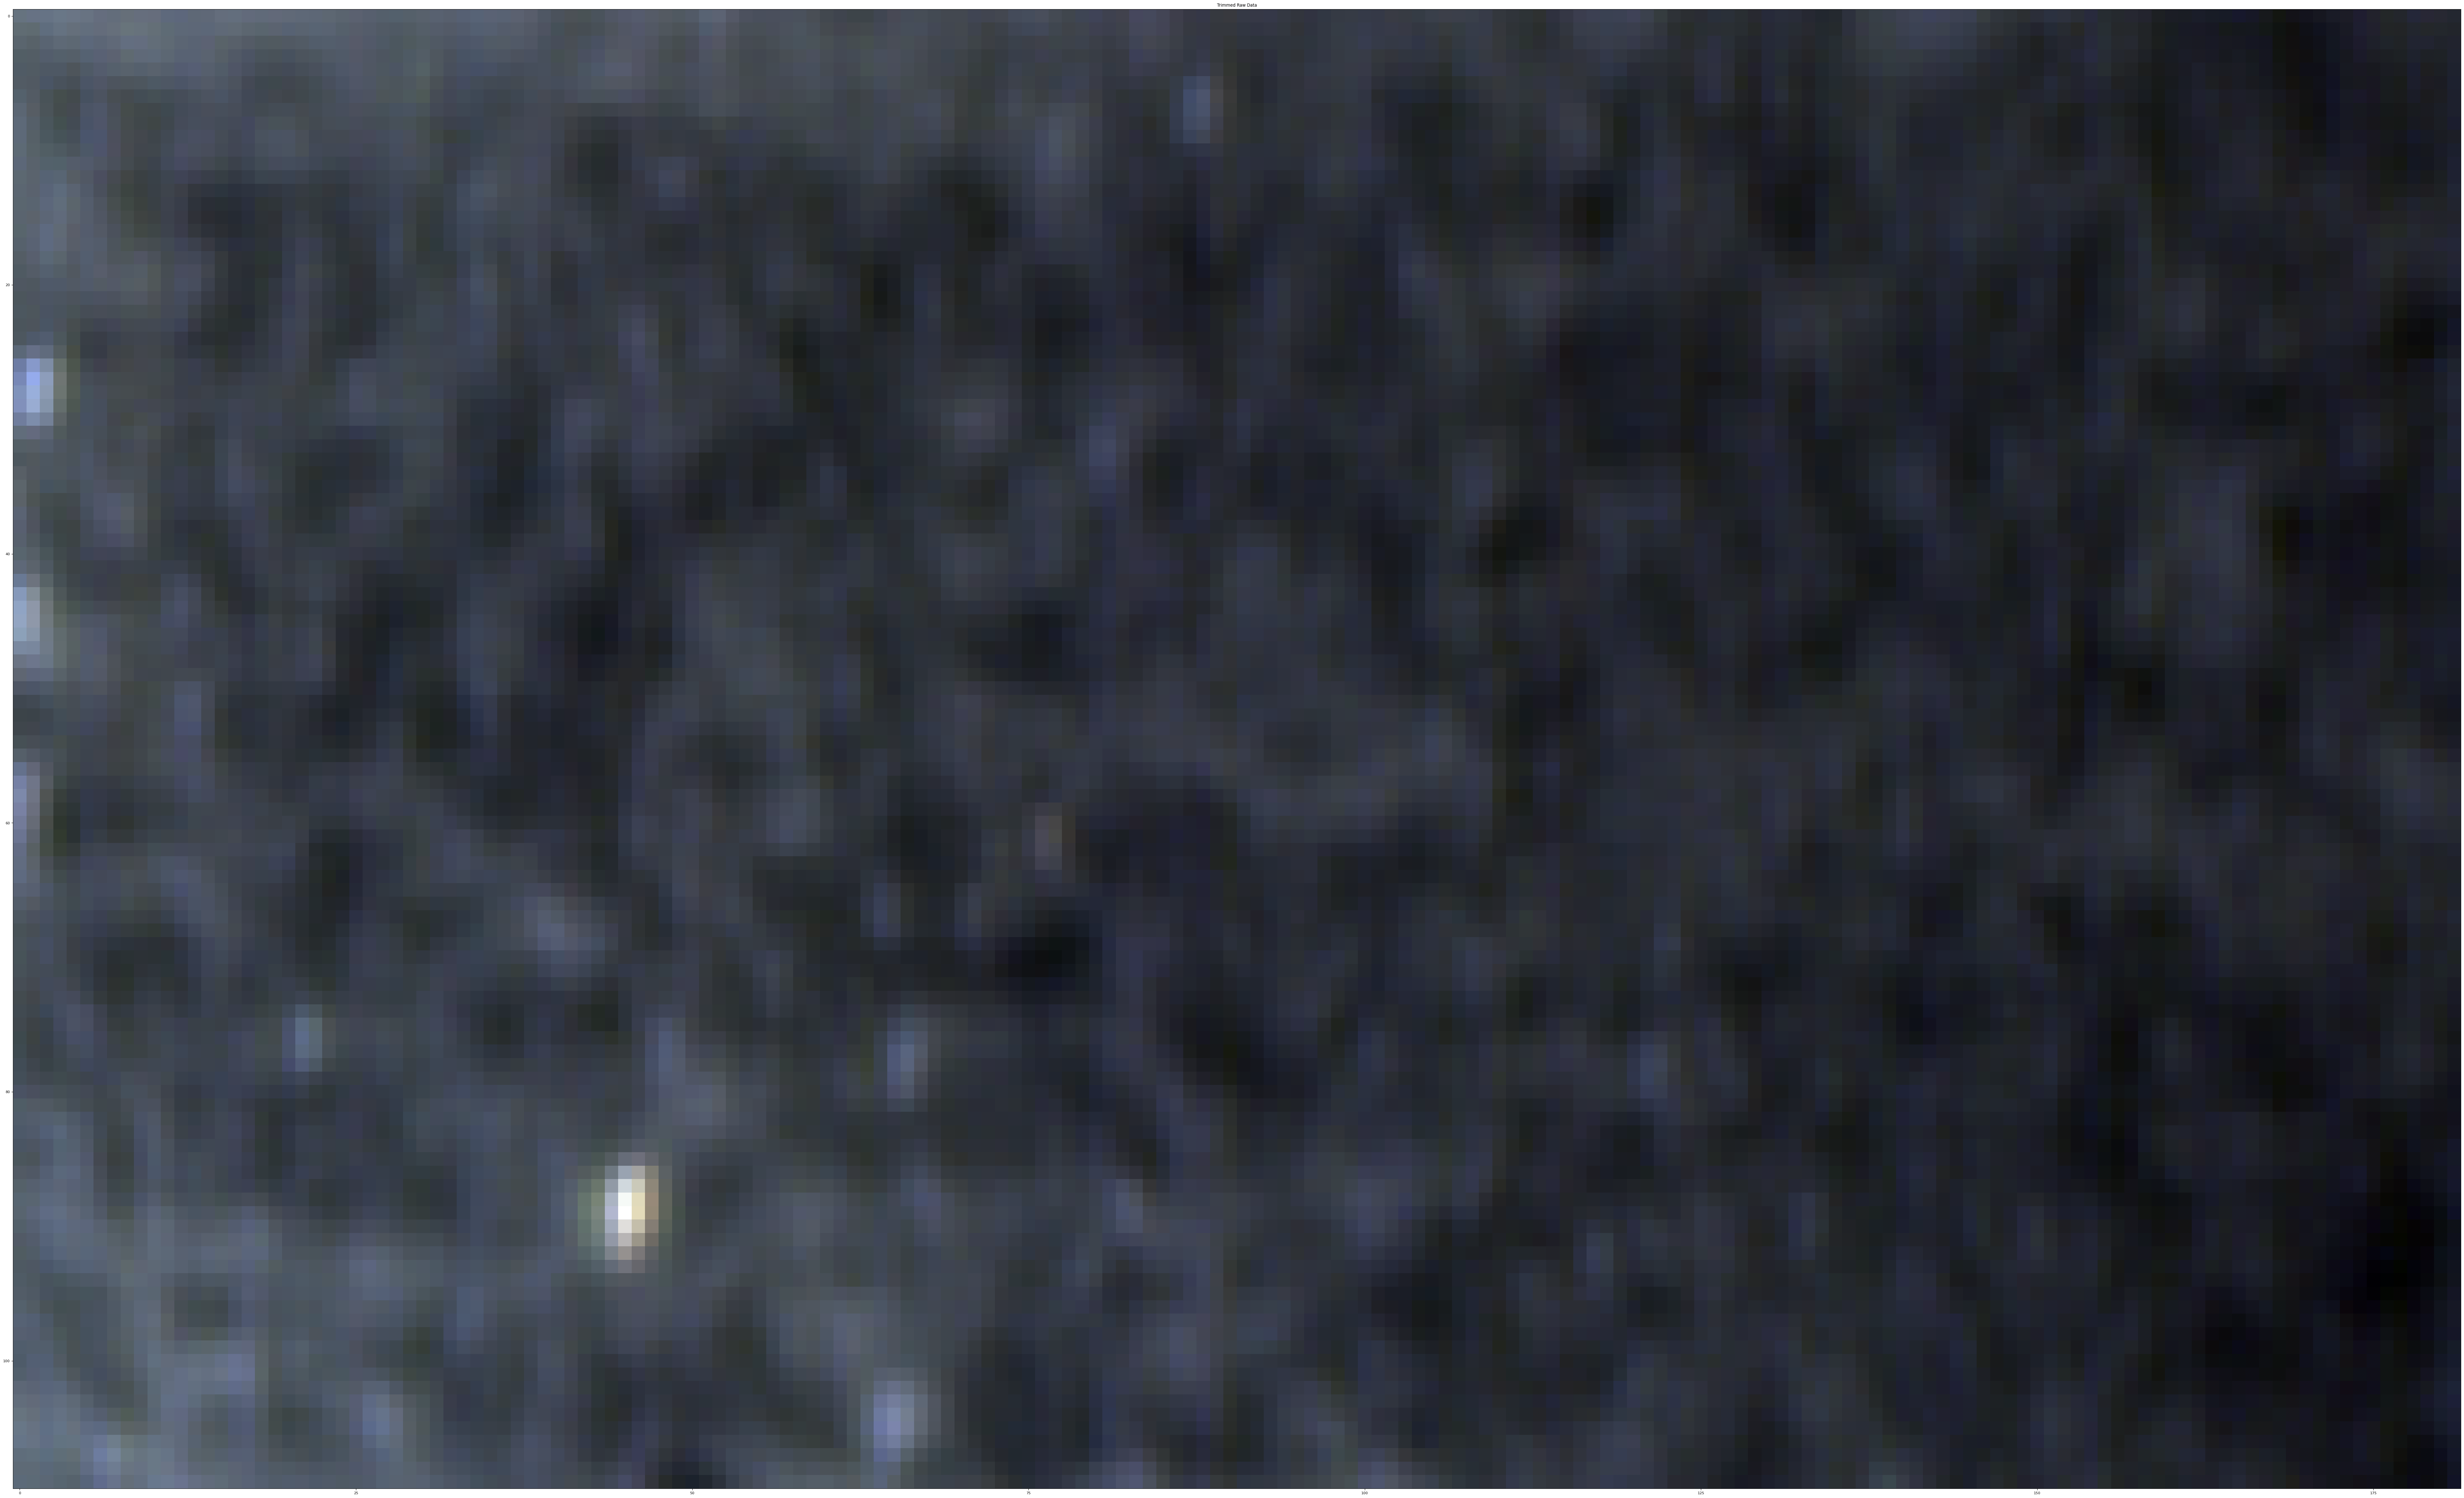

In [7]:
trimmedData = processice.trim(data_nparr, w_ref, d_ref, px_dims, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)

In [8]:
print("WVs: ", wvls)

WVs:  [ 397.66  400.28  402.89  405.51  408.13  410.75  413.38  416.    418.62
  421.24  423.87  426.49  429.12  431.75  434.37  437.    439.63  442.26
  444.89  447.52  450.16  452.79  455.43  458.06  460.7   463.34  465.98
  468.62  471.26  473.9   476.54  479.19  481.83  484.48  487.12  489.77
  492.41  495.06  497.72  500.37  503.01  505.67  508.33  510.98  513.63
  516.29  518.94  521.61  524.26  526.92  529.59  532.25  534.91  537.58
  540.24  542.9   545.57  548.24  550.9   553.58  556.25  558.92  561.59
  564.26  566.94  569.61  572.29  574.96  577.64  580.32  583.    585.68
  588.36  591.04  593.73  596.41  599.1   601.78  604.47  607.15  609.85
  612.54  615.22  617.91  620.61  623.31  626.    628.69  631.38  634.09
  636.79  639.48  642.18  644.88  647.59  650.29  652.99  655.69  658.4
  661.11  663.82  666.52  669.23  671.94  674.65  677.36  680.08  682.79
  685.5   688.22  690.93  693.65  696.37  699.09  701.81  704.53  707.25
  709.97  712.7   715.42  718.15  720.88  723.

In [9]:
print("Violet WV: ", wvls[9])
print("Green  WV: ", wvls[47])
print("IR WV: ", wvls[215])

Violet WV:  421.24
Green  WV:  521.61
IR WV:  981.28


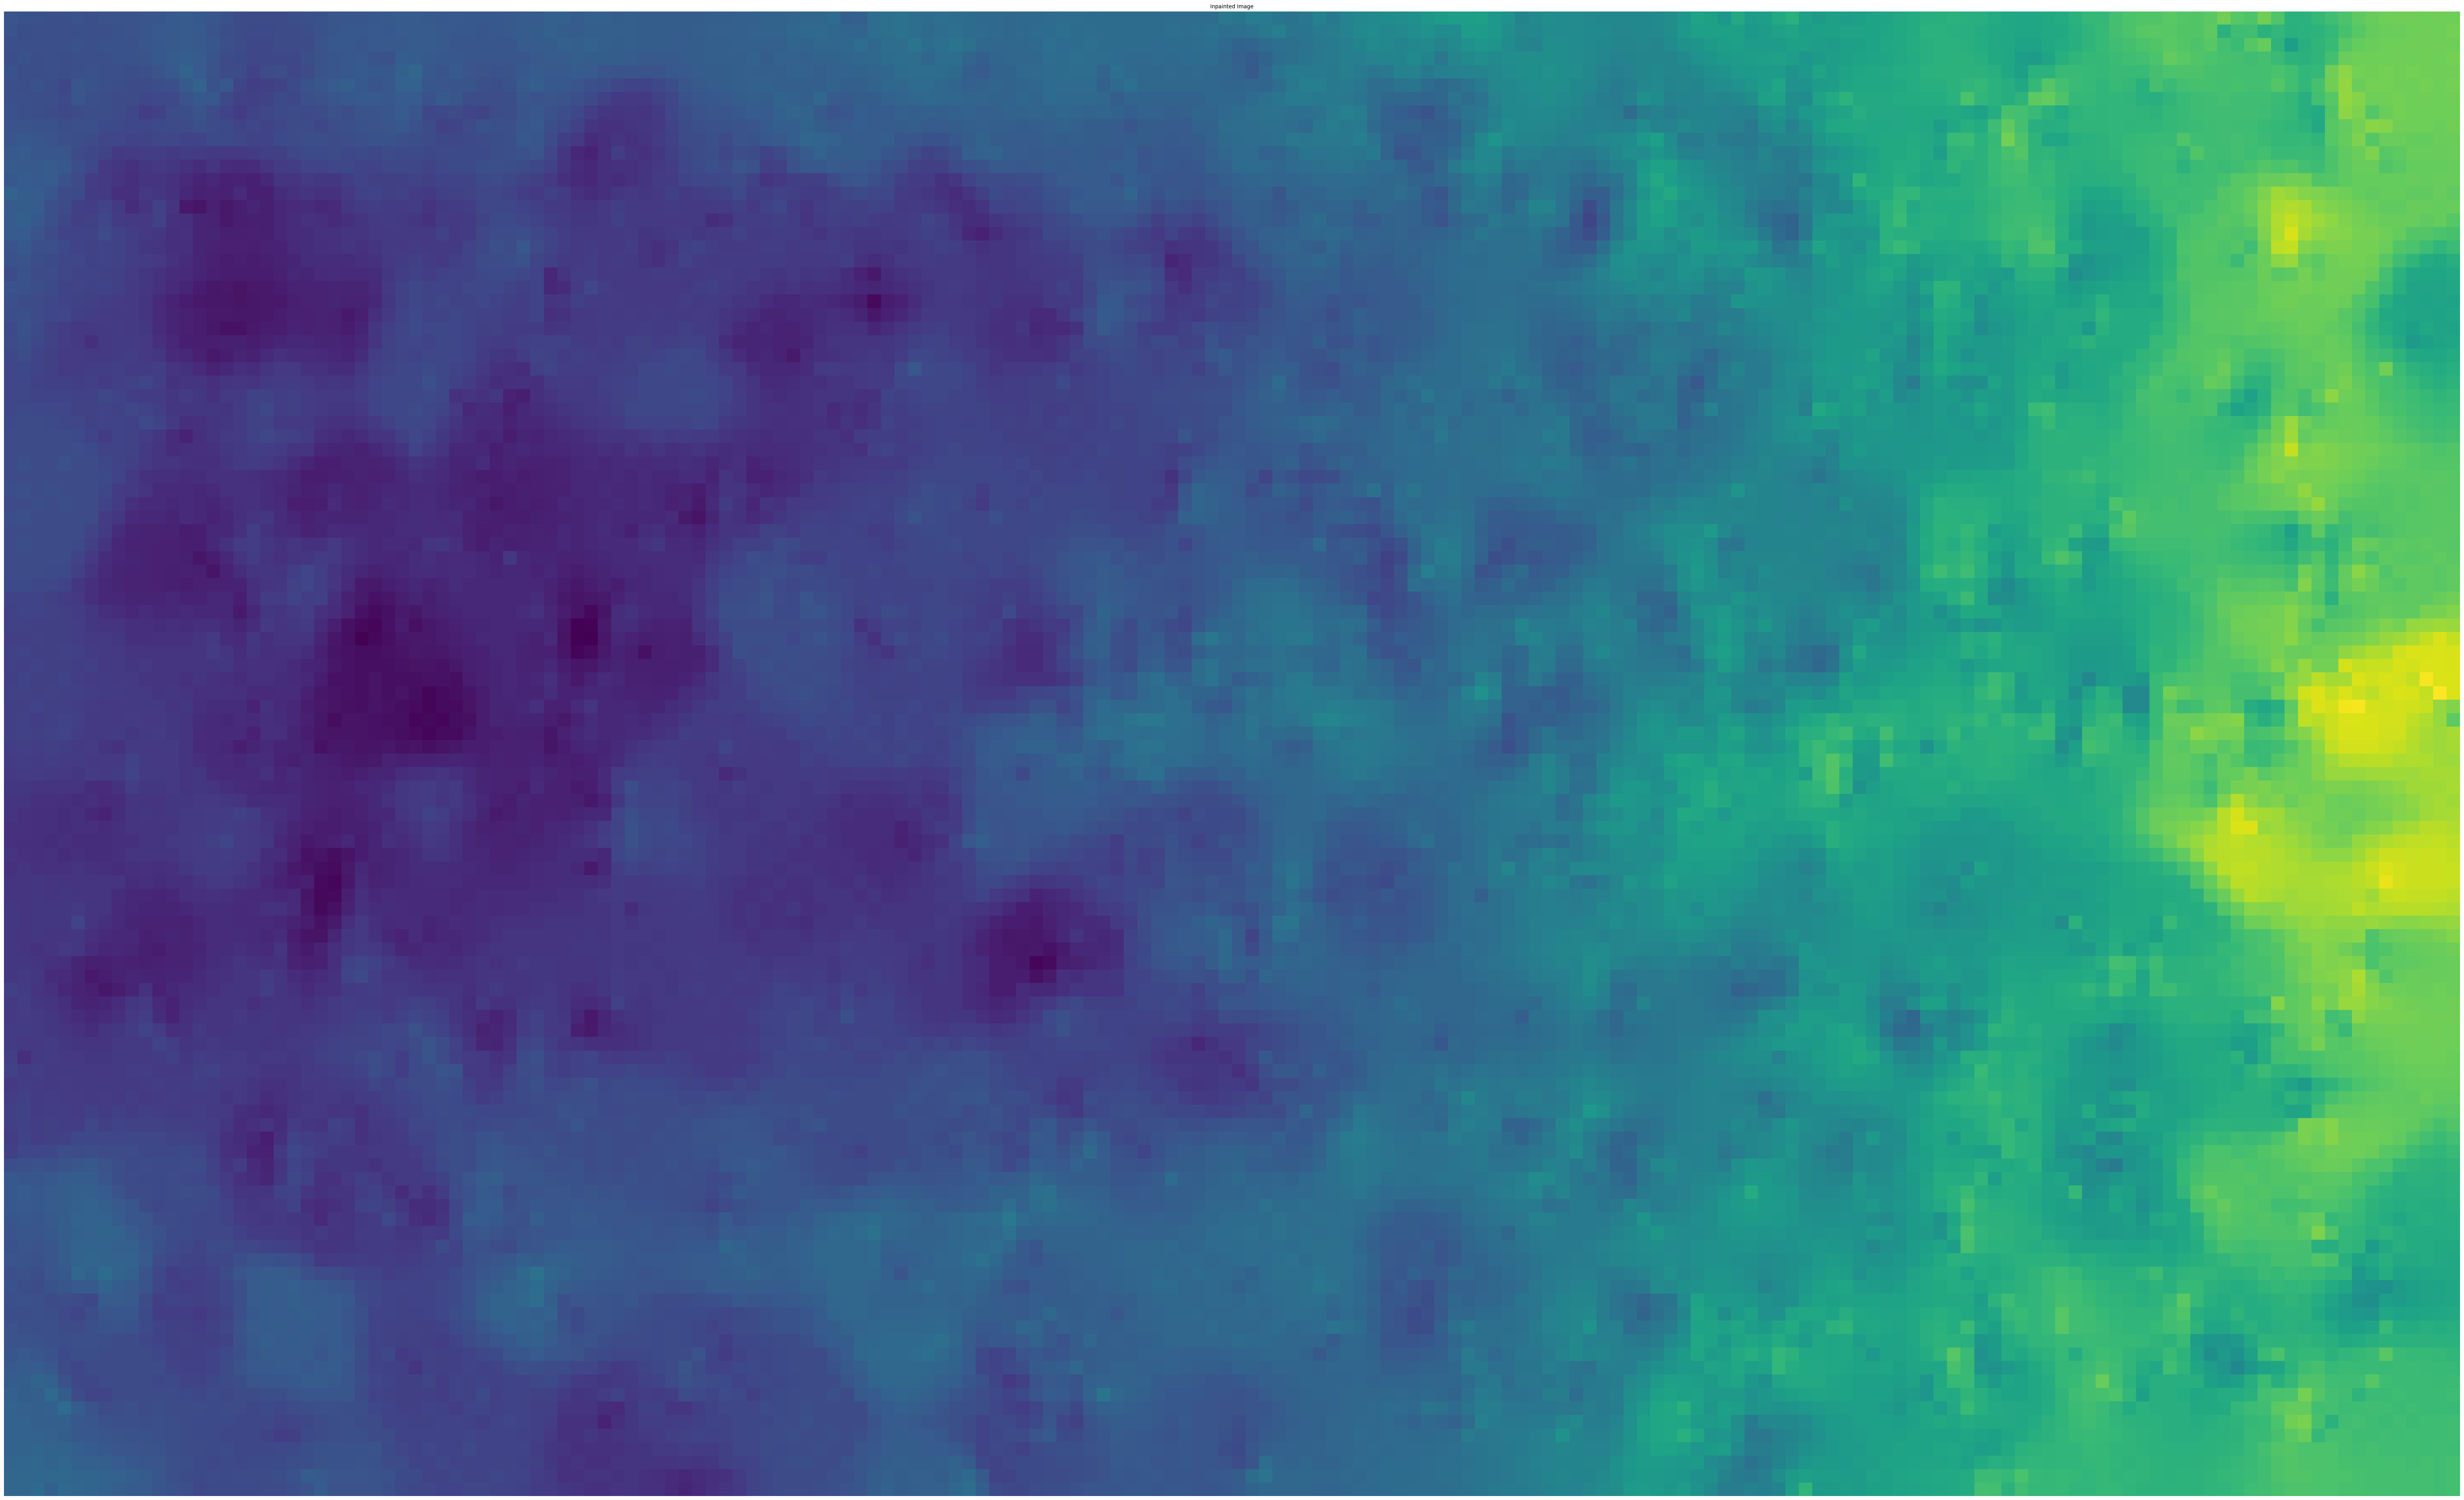

In [10]:
inpainted_img = processice.bubbles(correctedData,  fwhm)

In [11]:
violet = inpainted_img[:, :, 9] 
infrared = inpainted_img[:, :, 215] 
green = inpainted_img[:, :, 110] 

In [12]:
print("Violet Shape: ", violet.shape)
height, _ = violet.shape
depths_cm = top_depth * 100 + (np.arange(height) / px_per_cm)

row_sums = np.sum(violet, axis=1)
row_mean = np.mean(violet, axis=1)
row_median = np.median(violet, axis=1)


data = {"Depth_cm": depths_cm, "Sums": row_sums, "Means": row_mean, "Medians": row_median}

violet_df = pd.DataFrame(data)

violet_df = violet_df[(violet_df.select_dtypes(include='number') >= 0).all(axis=1)]

Violet Shape:  (110, 182)


In [13]:
height, _ = infrared.shape
depths_cm = top_depth * 100 + (np.arange(height) / px_per_cm)

row_sums = np.sum(infrared, axis=1)
row_mean = np.mean(infrared, axis=1)
row_median = np.median(infrared, axis=1)


data = {"Depth_cm": depths_cm, "Sums": row_sums, "Means": row_mean, "Medians": row_median}

infrared_df = pd.DataFrame(data)

infrared_df = infrared_df[(infrared_df.select_dtypes(include='number') >= 0).all(axis=1)]

In [14]:
height, _ = green.shape
depths_cm = top_depth * 100 + (np.arange(height) / px_per_cm)

row_sums = np.sum(green, axis=1)
row_mean = np.mean(green, axis=1)
row_median = np.median(green, axis=1)


data = {"Depth_cm": depths_cm, "Sums": row_sums, "Means": row_mean, "Medians": row_median}

green_df = pd.DataFrame(data)

green_df = green_df[(green_df.select_dtypes(include='number') >= 0).all(axis=1)]

In [15]:
print(violet_df)

         Depth_cm       Sums     Means   Medians
0    16517.700000  34.142129  0.187594  0.180708
1    16517.715631  33.972636  0.186663  0.177193
2    16517.731262  33.978417  0.186695  0.175681
3    16517.746892  33.808345  0.185760  0.173970
4    16517.762523  33.537625  0.184273  0.173209
..            ...        ...       ...       ...
105  16519.341231  31.653023  0.173918  0.161992
106  16519.356862  31.876900  0.175148  0.164273
107  16519.372492  32.030817  0.175993  0.166555
108  16519.388123  32.048830  0.176092  0.166555
109  16519.403754  32.219774  0.177032  0.167696

[110 rows x 4 columns]


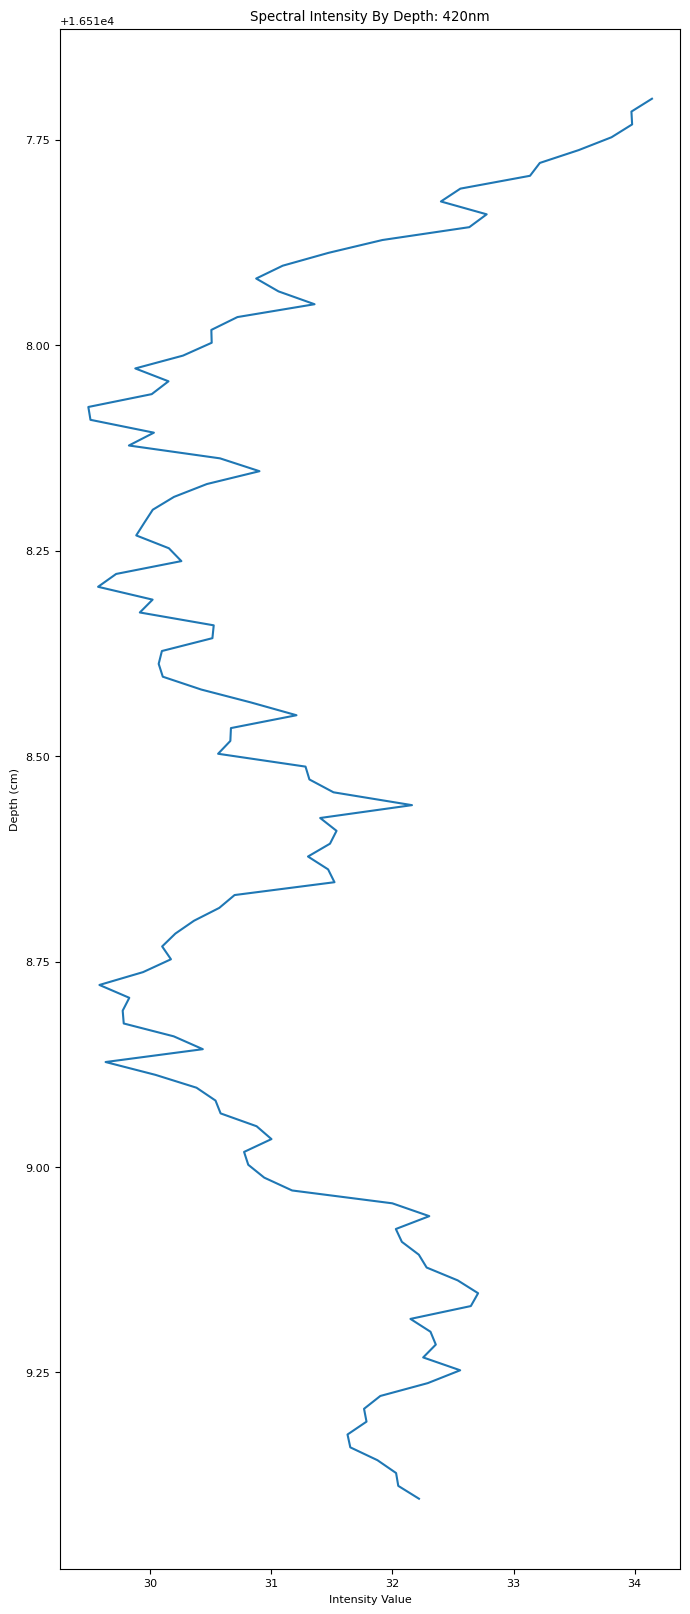

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 20))
plt.plot(violet_df["Sums"], violet_df["Depth_cm"], label='400nm')
plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Intensity Value')
plt.ylabel('Depth (cm)')
plt.title("Spectral Intensity By Depth: 420nm")
plt.show()

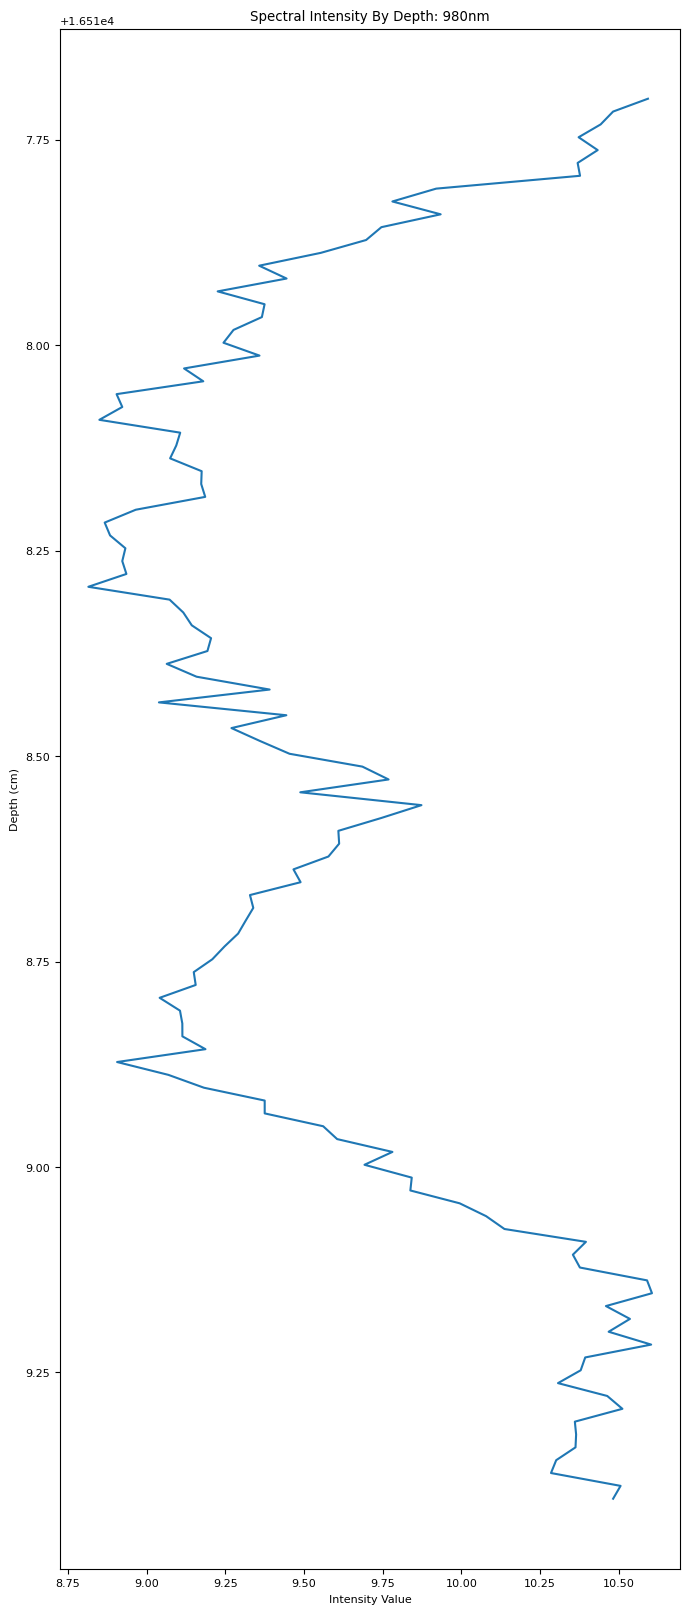

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 20))
plt.plot(infrared_df["Sums"], infrared_df["Depth_cm"], label='520nm')
plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Intensity Value')
plt.ylabel('Depth (cm)')
plt.title("Spectral Intensity By Depth: 980nm")
plt.show()

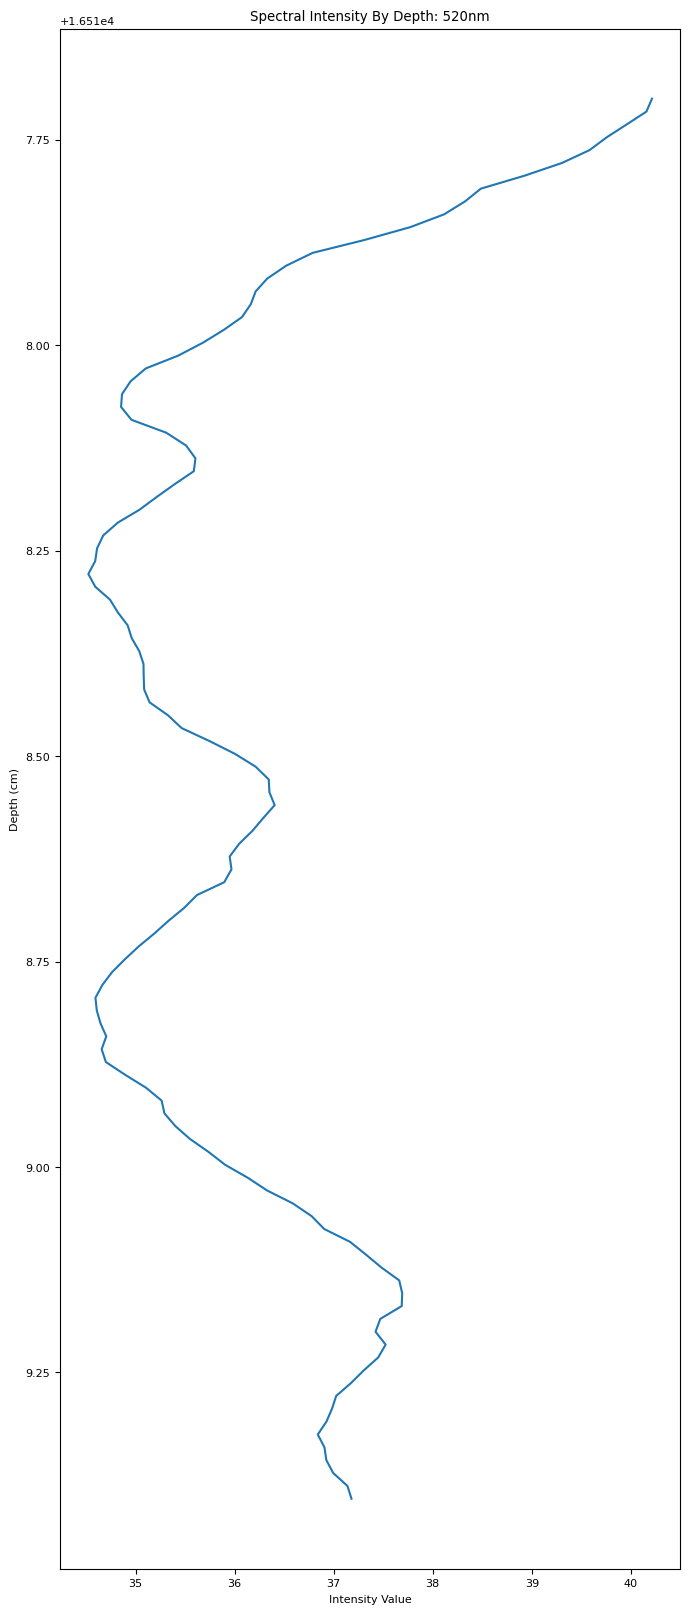

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 20))
plt.plot(green_df["Sums"], green_df["Depth_cm"], label='980nm')
plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Intensity Value')
plt.ylabel('Depth (cm)')
plt.title("Spectral Intensity By Depth: 520nm")
plt.show()

In [19]:
import pandas as pd
from functools import reduce

dfs = [violet_df, green_df, infrared_df]

df_merged = reduce(lambda left, right: pd.merge(left, right, on='Depth_cm', how='outer', suffixes=('', '_drop')), dfs)

df_merged.columns = [
    'Depth_cm', 
    'Sums_1', 'Means_1', 'Medians_1',
    'Sums_2', 'Means_2', 'Medians_2',
    'Sums_3', 'Means_3', 'Medians_3'
]

In [20]:
# img_short = correctedData[:, :, 0:3]      #400nm
# fwhm_short = fwhm[0:3]

# img_mid = correctedData[:, :, 110:113]
# fwhm_mid = fwhm[110:113]

# img_long = correctedData[:, :, 221:224]   #1000nm
# fwhm_long = fwhm[221:224]

In [21]:
# inpainted_short = processice.bubbles(img_short,  fwhm_short)

# inpainted_mid = processice.bubbles(img_mid,  fwhm_mid)

# inpainted_long = processice.bubbles(img_long,  fwhm_long)

In [22]:
# sums_img_short, full_img_sums_short = processSums.channel_sums(inpainted_short, px_per_cm, top_depth, Debug, Save, outputPath)
# combined_df_short, per_section_short = processSums.sum_comparison(inpainted_short, px_per_cm, top_depth, Debug, True, outputPath)

In [23]:
# sums_img_mid, full_img_sums_mid = processSums.channel_sums(inpainted_mid, px_per_cm, top_depth, Debug, Save, outputPath)
# combined_df_mid, per_section_mid = processSums.sum_comparison(inpainted_mid, px_per_cm, top_depth, Debug, True, outputPath)

In [24]:
# sums_img_long, full_img_sums_long = processSums.channel_sums(inpainted_long, px_per_cm, top_depth, Debug, Save, outputPath)
# combined_df_long, per_section_long = processSums.sum_comparison(inpainted_long, px_per_cm, top_depth, Debug, True, outputPath)

In [25]:
# fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# ax[0].imshow(sums_img_short, cmap='gray')
# ax[0].set_title('400nm')

# ax[1].imshow(sums_img_mid, cmap='gray')
# ax[1].set_title('650nm')

# ax[2].imshow(sums_img_long, cmap='gray')
# ax[2].set_title('1000nm')

In [26]:
# import pandas as pd
# from functools import reduce

# dfs = [full_img_sums_short, full_img_sums_mid, full_img_sums_long]

# df_merged = reduce(lambda left, right: pd.merge(left, right, on='Depth_cm', how='outer', suffixes=('', '_drop')), dfs)

# df_merged.columns = [
#     'Depth_cm', 
#     'Sums_1', 'Means_1', 'Medians_1',
#     'Sums_2', 'Means_2', 'Medians_2',
#     'Sums_3', 'Means_3', 'Medians_3'
# ]

In [27]:
# print(df_merged)

In [28]:
df_merged['Diff_1_2_Means'] = df_merged['Means_1'] - df_merged['Means_2']
df_merged['Diff_1_3_Means'] = df_merged['Means_1'] - df_merged['Means_3']
df_merged['Diff_2_3_Means'] = df_merged['Means_2'] - df_merged['Means_3']

df_merged['Means_Spread'] = df_merged[['Means_1', 'Means_2', 'Means_3']].max(axis=1) - \
                             df_merged[['Means_1', 'Means_2', 'Means_3']].min(axis=1)

differences_only = df_merged[df_merged['Means_Spread'] > 0]

In [29]:
# BG_NDI=(S420−S520)/(S420+S520) for blue-specific absorption (soot/organics) and fine-particle effects.
# VN_NDI=(S520−S980)/(S520+S980) strong dust/scattering signature in visible vs NIR (common for mineral dust).

df_merged['BG_NDI'] = (df_merged['Means_1'] - df_merged['Means_2'])/(df_merged['Means_1'] + df_merged['Means_2'])
df_merged['VN_NDI'] = (df_merged['Means_2'] - df_merged['Means_3'])/(df_merged['Means_2'] + df_merged['Means_3'])


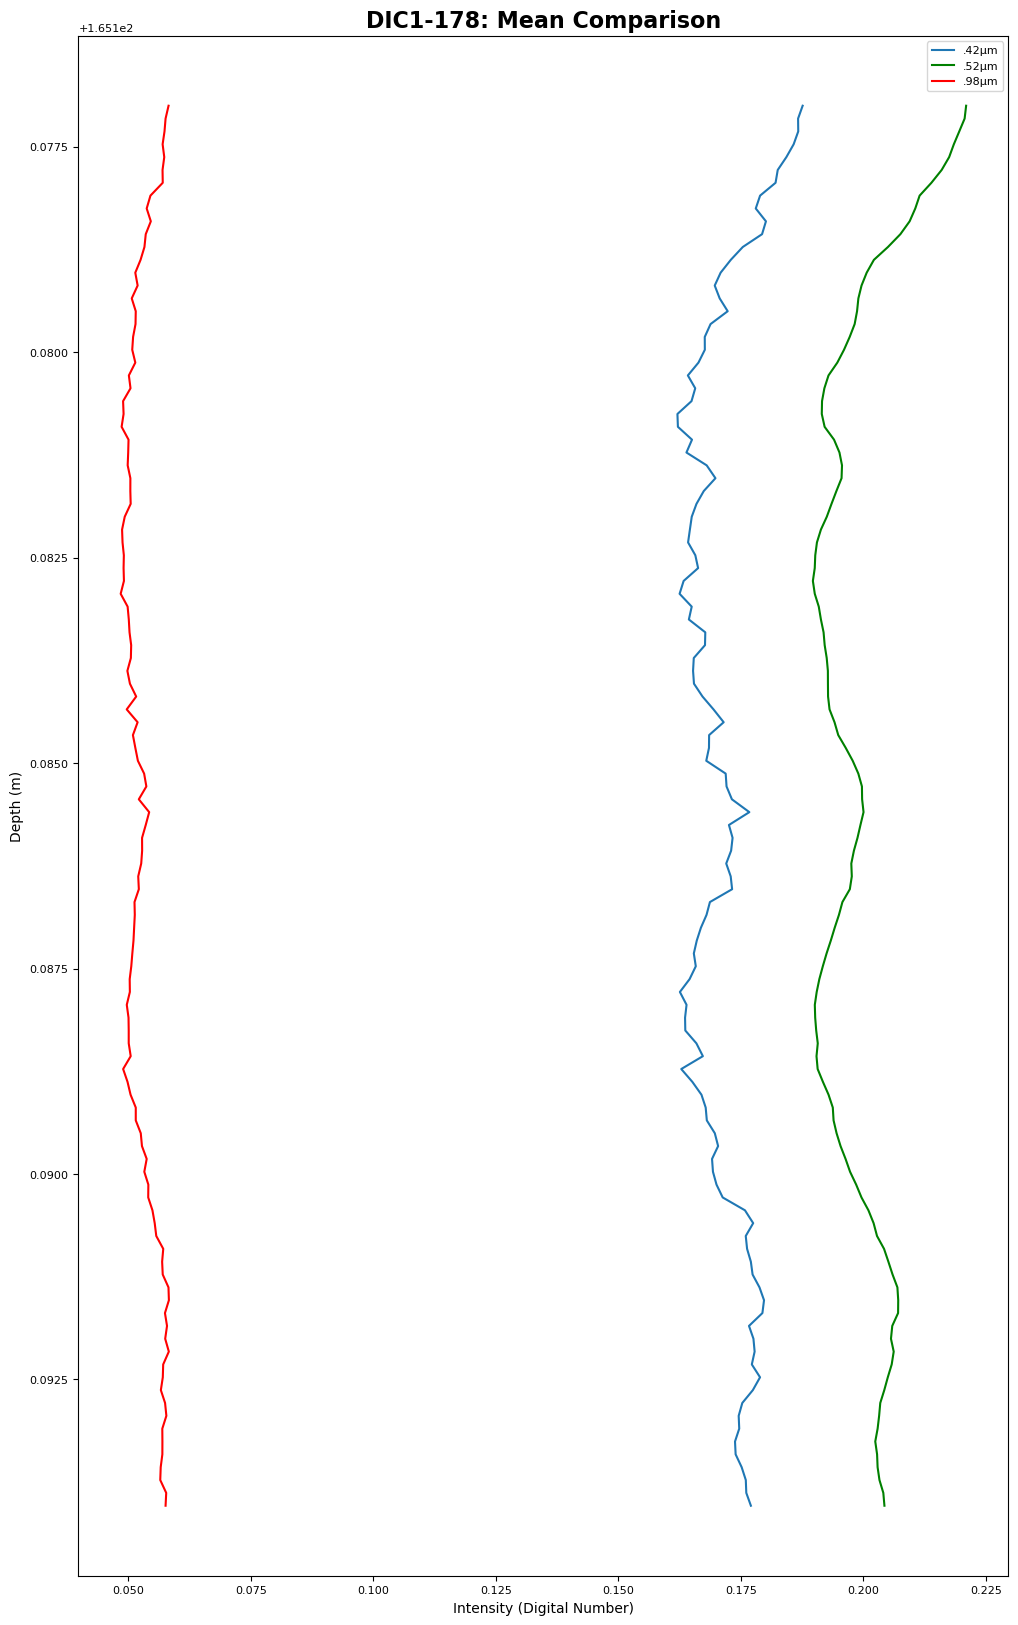

In [30]:
import matplotlib.pyplot as plt

df_merged['Depth_cm'] = df_merged['Depth_cm'] / 100

plt.figure(figsize=(12, 20))
plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='.42µm')
plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='.52µm', color="green")
plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='.98µm', color="red")
plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Intensity (Digital Number)', fontsize=10)
plt.ylabel('Depth (m)', fontsize=10)
plt.legend()
plt.title(f'{dataName}: Mean Comparison', fontsize=16, fontweight='bold')
out_path = f"{outputPath}/WVL_meanSignalComparison.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [31]:
# plt.figure(figsize=(8, 15))
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference')
# plt.xlabel('Mean Value Difference')
# plt.ylabel('Depth (cm)')
# plt.gca().invert_yaxis()
# plt.title('Difference in Means across Depths: 400 vs 1000nm')
# plt.show()

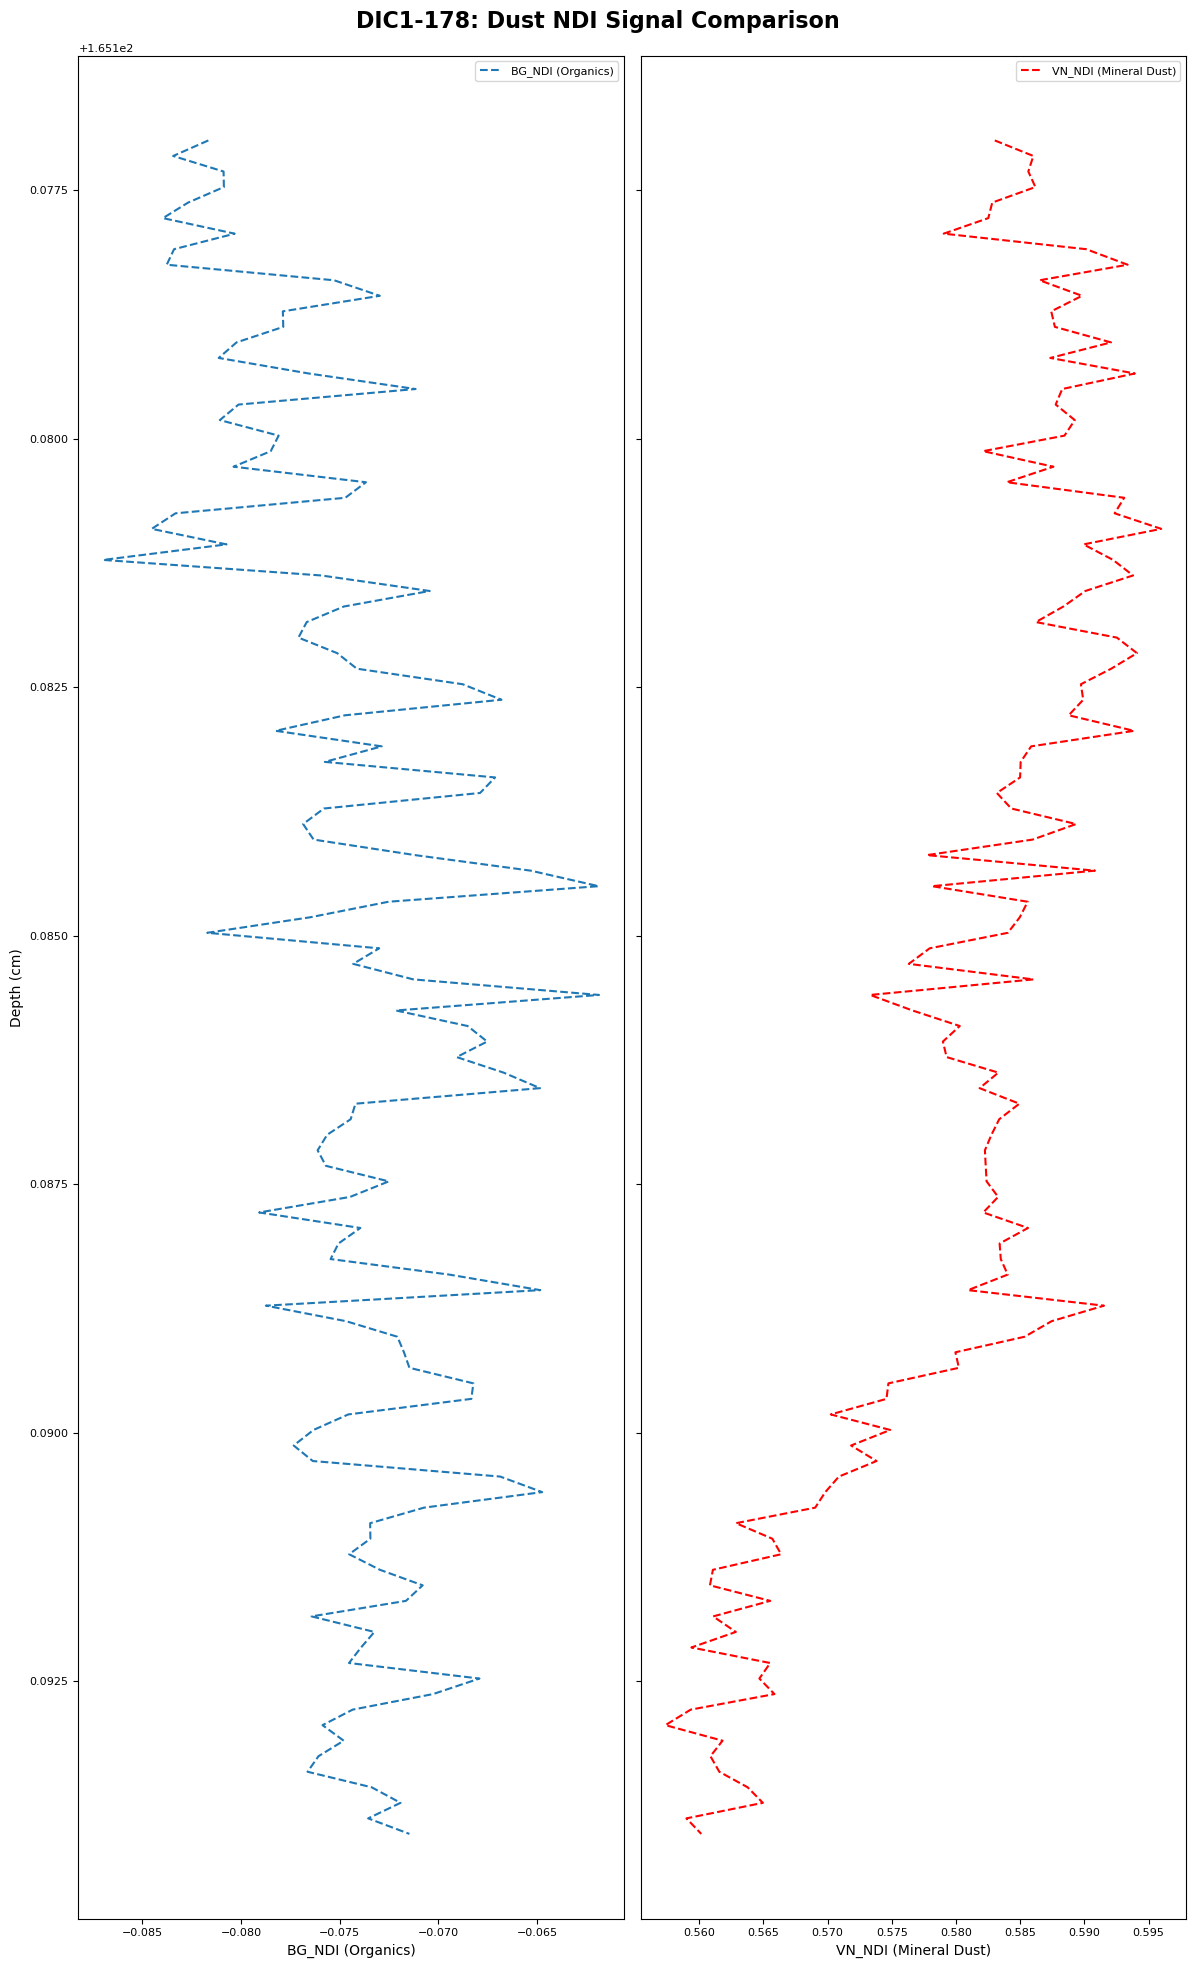

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 20), sharey=True)

# BG_NDI plot
ax1.plot(df_merged['BG_NDI'], df_merged['Depth_cm'],
         label='BG_NDI (Organics)', linestyle='dashed')
ax1.set_xlabel('BG_NDI (Organics)', fontsize=10)
ax1.set_ylabel('Depth (cm)', fontsize=10)
ax1.invert_yaxis()
ax1.legend()

# VN_NDI plot
ax2.plot(df_merged['VN_NDI'], df_merged['Depth_cm'],
         label='VN_NDI (Mineral Dust)', linestyle='dashed', color="red")
ax2.set_xlabel('VN_NDI (Mineral Dust)', fontsize=10)
ax2.legend()

plt.suptitle(f'{dataName}: Dust NDI Signal Comparison\n',
             fontsize=16, fontweight='bold')

plt.tight_layout()

out_path = f"{outputPath}/NDI_SignalComparison.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

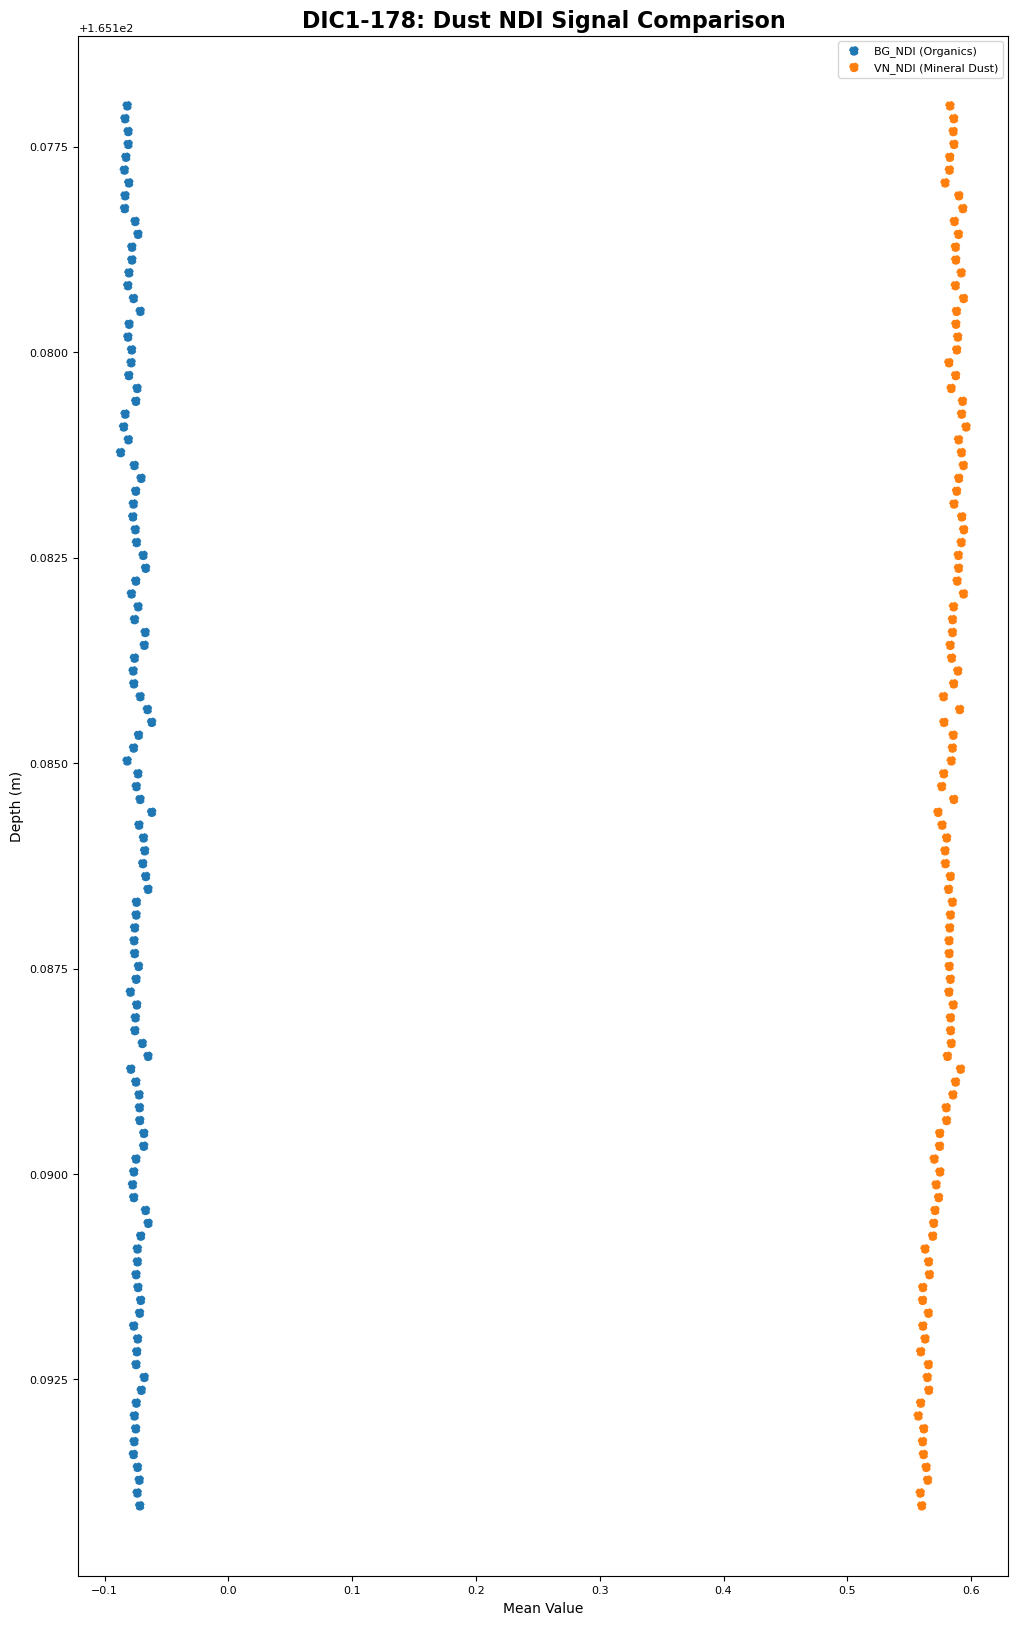

In [33]:
plt.figure(figsize=(12, 20))
# plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='420nm')
# plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='520nm')
# plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='980nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference 1-3', linestyle='dashed')
# plt.plot(df_merged['Diff_1_2_Means'], df_merged['Depth_cm'], label='Difference 1-2', linestyle='dashed')
# plt.plot(df_merged['Diff_2_3_Means'], df_merged['Depth_cm'], label='Difference 2-3', linestyle='dashed')
# plt.scatter(df_merged['BG_NDI'], df_merged['Depth_cm'], label='BG_NDI (Organics)', linestyle='dashed')
# plt.scatter(df_merged['VN_NDI'], df_merged['Depth_cm'], label='VN_NDI (Mineral Dust)', linestyle='dashed')
ax.barh(df_merged['Depth_cm'], df_merged['BG_NDI'], height=1)
ax.barh(df_merged['Depth_cm'], df_merged['VN_NDI'], height=1)

plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Mean Value', fontsize=10)
plt.ylabel('Depth (m)', fontsize=10)
plt.legend()
plt.title(f'{dataName}: Dust NDI Signal Comparison', fontsize=16, fontweight='bold')
out_path = f"{outputPath}/NDI_SignalComparison.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

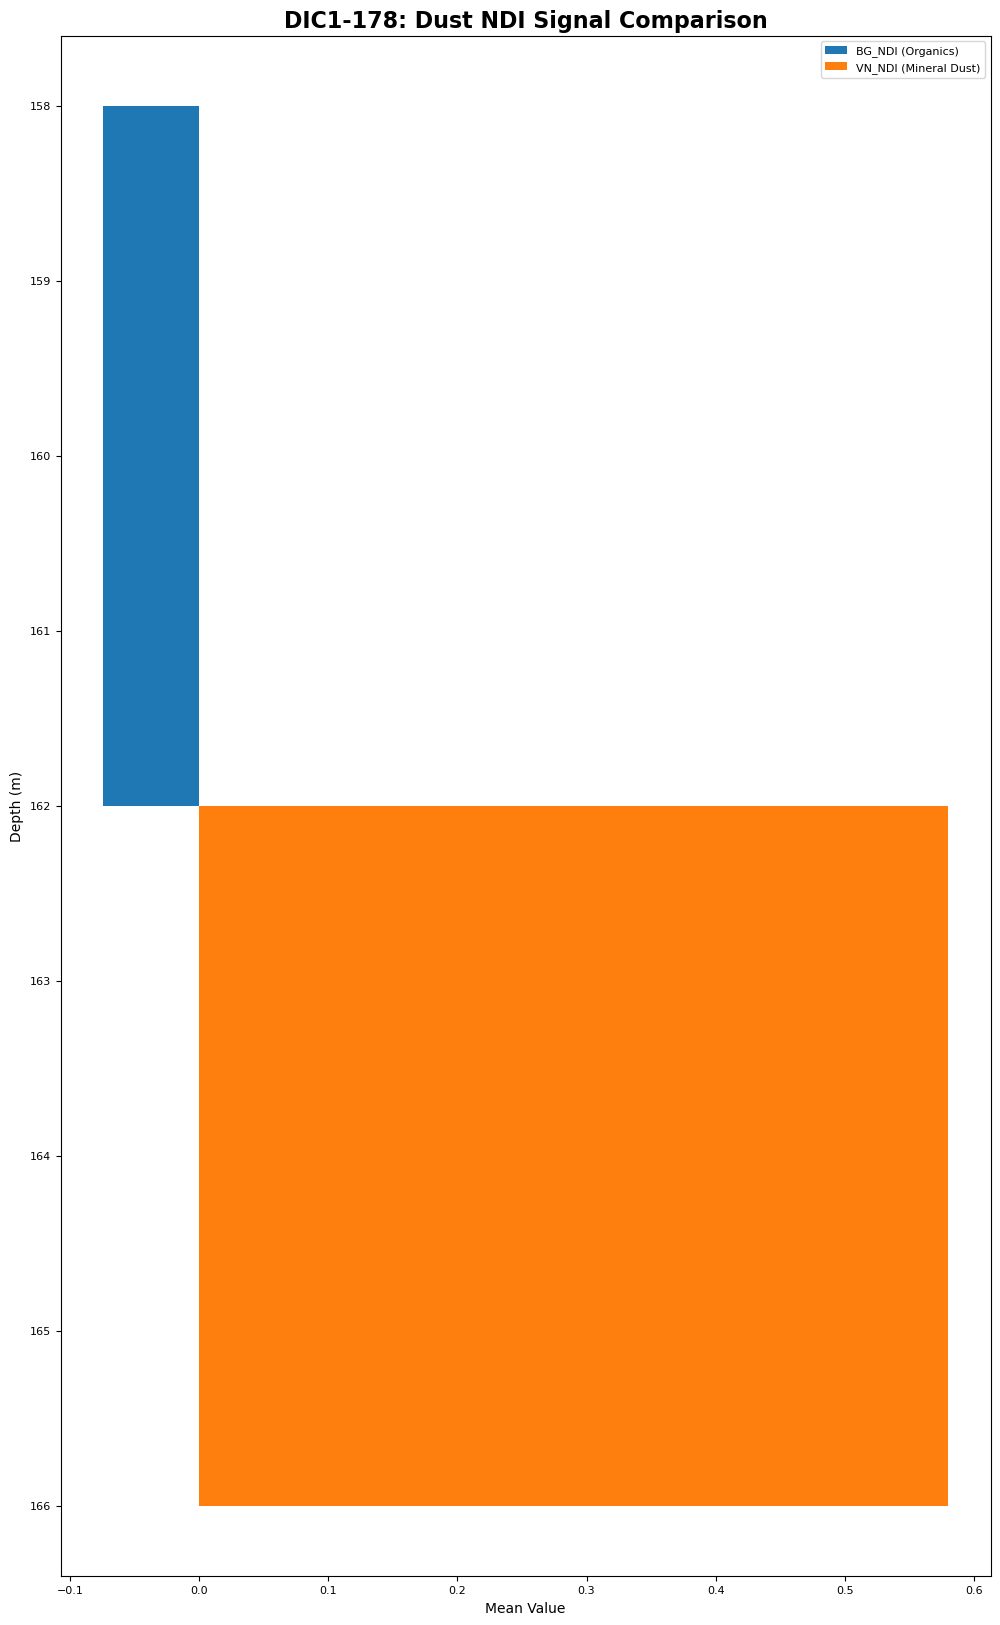

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ---- Bin depth ----
bin_size = 10  # cm (adjust as needed)
df = df_merged.copy()

df["depth_bin"] = (df["Depth_cm"] // bin_size) * bin_size

# Compute mean per bin
binned = df.groupby("depth_bin")[["BG_NDI", "VN_NDI"]].mean().reset_index()

# ---- Plot ----
fig, ax = plt.subplots(figsize=(12, 20))

bar_height = bin_size * 0.4  # controls thickness

ax.barh(
    binned["depth_bin"],
    binned["BG_NDI"],
    height=bar_height,
    label="BG_NDI (Organics)"
)

ax.barh(
    binned["depth_bin"] + bar_height,
    binned["VN_NDI"],
    height=bar_height,
    label="VN_NDI (Mineral Dust)"
)

# ---- Formatting ----
ax.invert_yaxis()
ax.set_xlabel("Mean Value", fontsize=10)
ax.set_ylabel("Depth (m)", fontsize=10)
ax.legend()
ax.set_title(f"{dataName}: Dust NDI Signal Comparison", fontsize=16, fontweight='bold')

out_path = f"{outputPath}/NDI_SignalComparison_bar.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")

plt.show()

In [35]:
# import matplotlib.image as mpimg
# from pathlib import Path


# # dir_path= "/data/icecores/Output/GL/GISP2/GISP2D/GISP2D-2088/HSIUM-176-2025-12-11_190503"

# # img_name = "HSIUM-176trimmed.png"

# dir_path = outputPath
# ing_name = 

# x_col= "BG_NDI"
# y_col= "Depth_cm"


# img_path = Path(str(dir_path + "/" + img_name))

# # --- Load data ---
# df = df_merged
# df['Depth_cm'] = df['Depth_cm'].values / 100
# img = mpimg.imread(img_path)
# H, W = img.shape[0], img.shape[1]

# # print(f"Image Shape: {img.shape}")
# # print(f"CSV Shape: {df.shape}")

# # --- Map data -> pixel space of the image ---
# x_min, x_max = float(df[x_col].min()), float(df[x_col].max())
# x_min = float(df['VN_NDI'].min())
# y_min, y_max = float(df[y_col].min()), float(df[y_col].max())

# def linmap(v, a0, a1, b0, b1):
#     return b0 + (np.asarray(v) - a0) * (b1 - b0) / (a1 - a0 + 1e-12)

# x_px = df[x_col]
# y_px = linmap(df[y_col], y_min, y_max, 0, H)

# # --- Plot ---
# fig, ax = plt.subplots(figsize=(8, 10))
# ax.imshow(img, extent=[x_min, x_max, H, 0], aspect="auto", interpolation="nearest", zorder=1)

# ax.plot(x_px, y_px, c="blue", linestyle='dashed', alpha=0.8, zorder=2)
# ax.plot(df_merged['VN_NDI'], y_px, c="red", linestyle='dashed', alpha=0.8, zorder=2)

# # --- Set y-axis ticks in real depth units ---
# n_ticks = 10
# pixel_ticks = np.linspace(0, H, n_ticks)
# depth_labels = np.linspace(y_min, y_max, n_ticks)
# ax.set_yticks(pixel_ticks)
# ax.set_yticklabels([f"{d:.1f}" for d in depth_labels])

# ax.set_xlabel('Pixel Intensity')
# ax.set_ylabel("Depth (m)")
# ax.set_title("GISP2D-2088: NDI Overlay")
# plt.tight_layout()
# out_path = outputPath / f"HSIUM-174_NDIByDepthOverlay.png"
# fig.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()

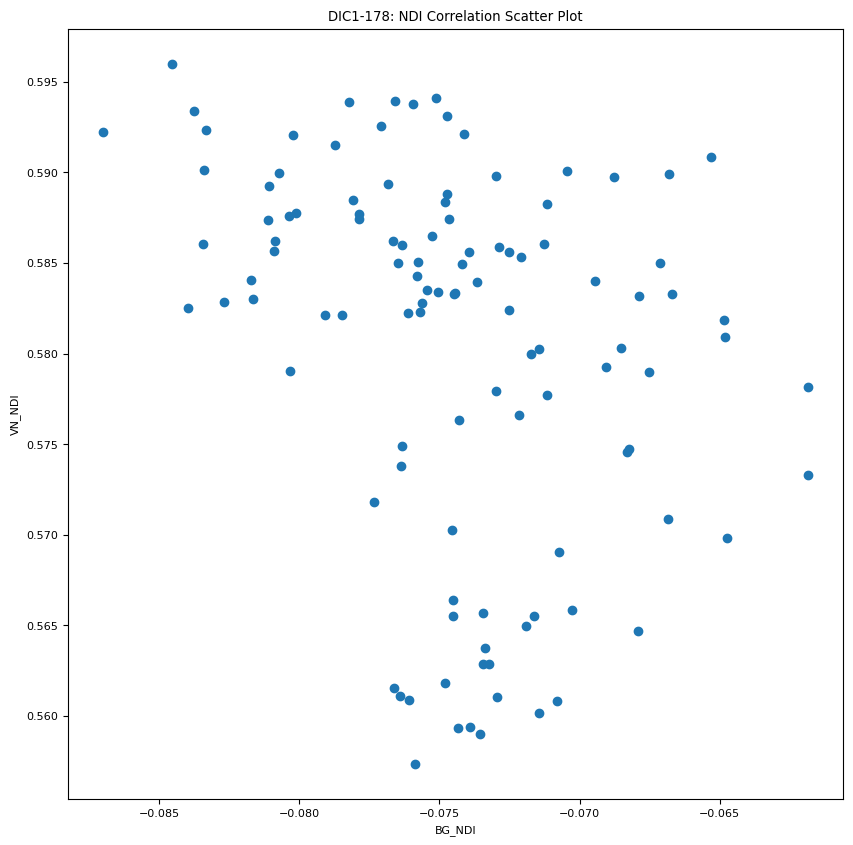

In [36]:
plt.figure(figsize=(10, 10))
plt.scatter(df_merged['BG_NDI'], df_merged['VN_NDI'])
# plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='1000nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('BG_NDI')
plt.ylabel('VN_NDI')
# plt.legend()
plt.title(f'{dataName}: NDI Correlation Scatter Plot')
out_path = f"{outputPath}/NDI_Correlation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

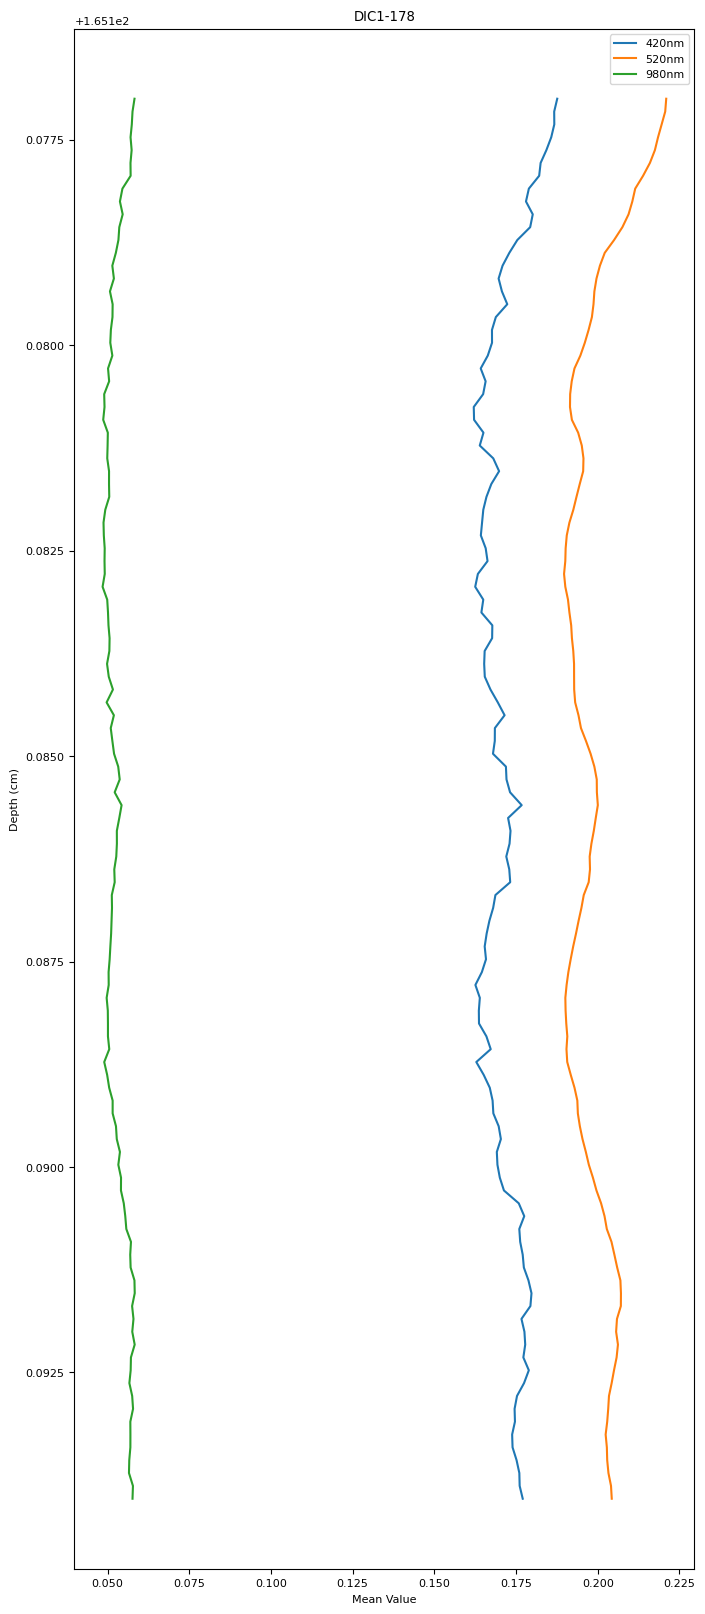

In [37]:
plt.figure(figsize=(8, 20))
plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='420nm')
plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='520nm')
plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='980nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference 1-3', linestyle='dashed')
# plt.plot(df_merged['Diff_1_2_Means'], df_merged['Depth_cm'], label='Difference 1-2', linestyle='dashed')
# plt.plot(df_merged['Diff_2_3_Means'], df_merged['Depth_cm'], label='Difference 2-3', linestyle='dashed')
# plt.plot(df_merged['BG_NDI'], df_merged['Depth_cm'], label='BG_NDI', linestyle='dashed')
# plt.plot(df_merged['VN_NDI'], df_merged['Depth_cm'], label='VN_NDI', linestyle='dashed')

plt.gca().invert_yaxis()  # Put 0 depth at the top
plt.xlabel('Mean Value')
plt.ylabel('Depth (cm)')
plt.legend()
plt.title(f'{dataName}')
out_path = f"{outputPath}/WVL_meanSignalComparison.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

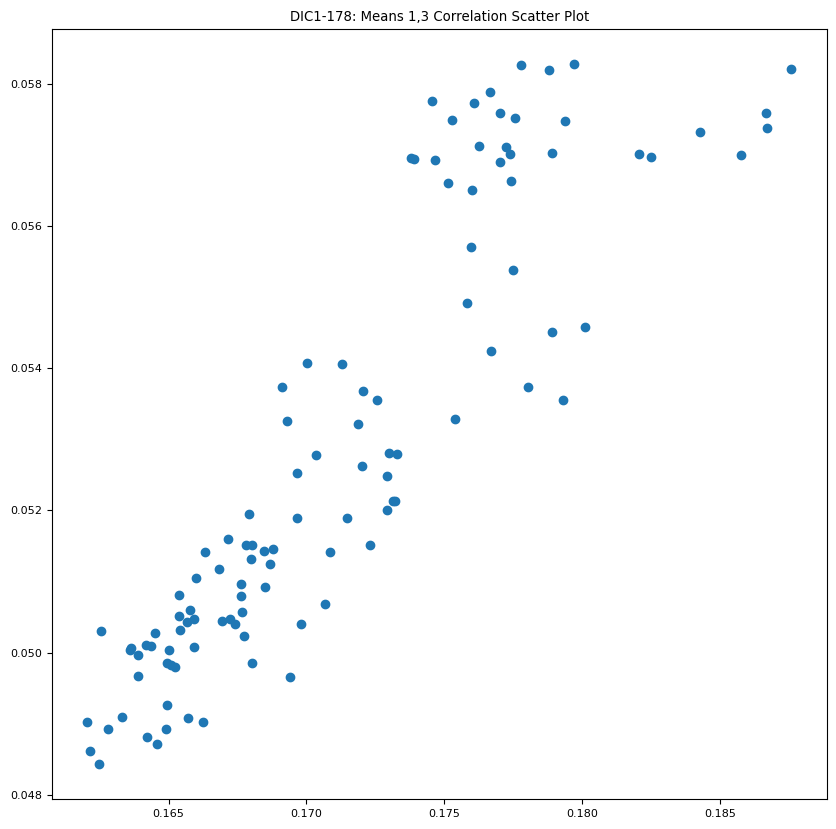

In [38]:
plt.figure(figsize=(10, 10))
plt.scatter(df_merged['Means_1'], df_merged['Means_3'])
# plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='1000nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
# plt.xlabel('Mean Value')
# plt.ylabel('Depth (cm)')
# plt.legend()
plt.title(f'{dataName}: Means 1,3 Correlation Scatter Plot')
out_path = f"{outputPath}/meanSignalCorrelation1-3.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

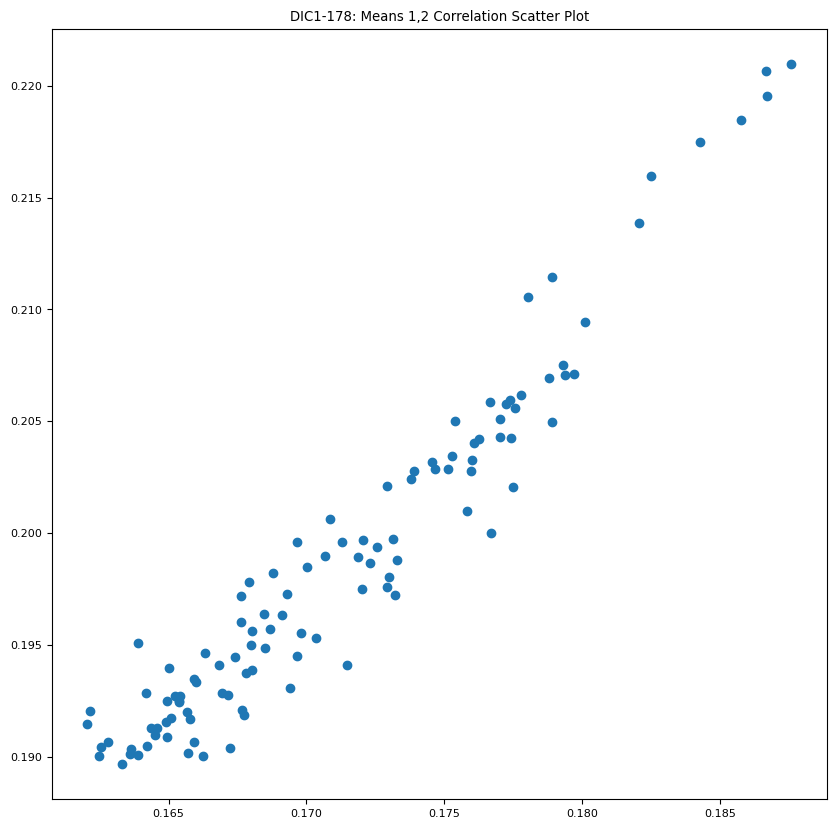

In [39]:
plt.figure(figsize=(10, 10))
plt.scatter(df_merged['Means_1'], df_merged['Means_2'])
# plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='1000nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
# plt.xlabel('Mean Value')
# plt.ylabel('Depth (cm)')
# plt.legend()
plt.title(f'{dataName}: Means 1,2 Correlation Scatter Plot')
out_path = f"{outputPath}/meanSignalCorrelation1-2.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

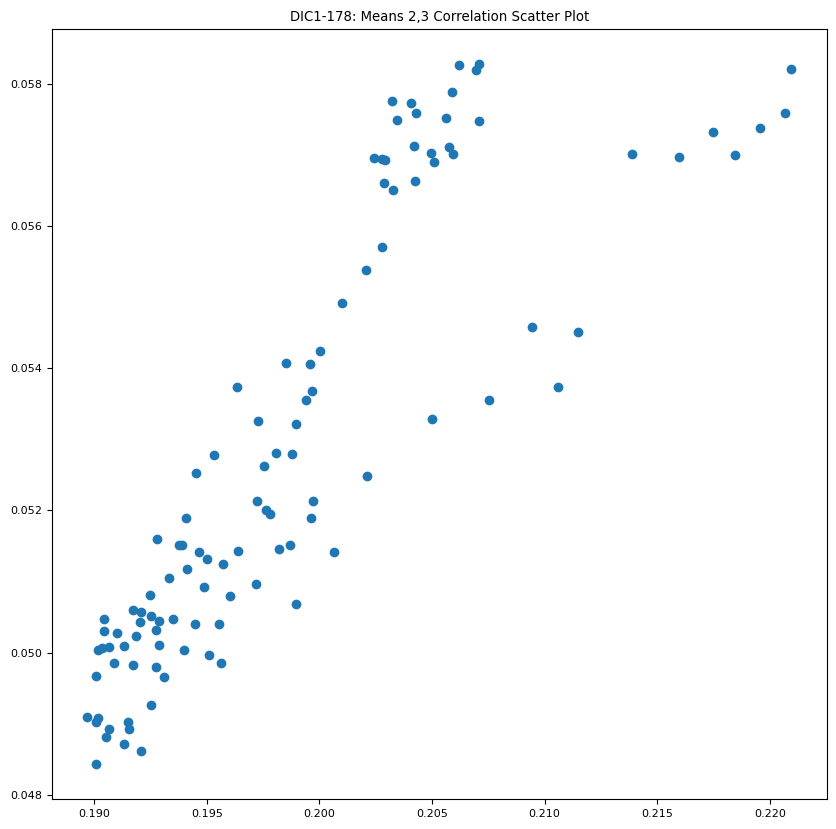

In [40]:
plt.figure(figsize=(10, 10))
plt.scatter(df_merged['Means_2'], df_merged['Means_3'])
# plt.plot(df_merged['Means_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Means_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Means_3'], df_merged['Depth_cm'], label='1000nm')
# plt.plot(df_merged['Diff_1_3_Means'], df_merged['Depth_cm'], label='Difference')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
# plt.xlabel('Mean Value')
# plt.ylabel('Depth (cm)')
# plt.legend()
plt.title(f'{dataName}: Means 2,3 Correlation Scatter Plot')
out_path = f"{outputPath}/meanSignalCorrelation2-3.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [41]:
# df_merged['Diff_1_2_Medians'] = df_merged['Medians_1'] - df_merged['Medians_2']
# df_merged['Diff_1_3_Medians'] = df_merged['Medians_1'] - df_merged['Medians_3']

# df_merged['Medians_Spread'] = df_merged[['Medians_1', 'Medians_2', 'Medians_3']].max(axis=1) - \
#                              df_merged[['Medians_1', 'Medians_2', 'Medians_3']].min(axis=1)

# differences_only = df_merged[df_merged['Medians_Spread'] > 0]

In [42]:
# plt.figure(figsize=(8, 20))
# plt.plot(df_merged['Medians_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Medians_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Medians_3'], df_merged['Depth_cm'], label='1000nm')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
# plt.xlabel('Median Value')
# plt.ylabel('Depth (cm)')
# plt.legend()
# plt.title('Comparison of Medians across Depths')
# plt.show()

In [43]:
# plt.figure(figsize=(8, 15))
# plt.plot(df_merged['Diff_1_3_Medians'], df_merged['Depth_cm'], label='Difference')
# plt.xlabel('Median Value Difference')
# plt.ylabel('Depth (cm)')
# plt.gca().invert_yaxis()
# plt.title('Difference in Medians across Depths: 400 vs 1000nm')
# plt.show()

In [44]:
# plt.figure(figsize=(8, 20))
# plt.plot(df_merged['Medians_1'], df_merged['Depth_cm'], label='400nm')
# plt.plot(df_merged['Medians_2'], df_merged['Depth_cm'], label='650nm')
# plt.plot(df_merged['Medians_3'], df_merged['Depth_cm'], label='1000nm')
# plt.plot(df_merged['Diff_1_3_Medians'], df_merged['Depth_cm'], label='Difference')
# plt.gca().invert_yaxis()  # Put 0 depth at the top
# plt.xlabel('Median Value')
# plt.ylabel('Depth (cm)')
# plt.legend()
# plt.title('Comparison of Median across Depths')
# out_path = f"{outputPath}/WVL_medianSignalComparison.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.show()